# GenAI Inference and Serving Architecture

This course covers the full spectrum of GenAI inference and serving — from model selection and the transformer inference pipeline, through batching and GPU scaling strategies, to cost engineering and advanced techniques such as speculative decoding, quantization, and attention optimization.

## Table of Contents

- [Module 01: Model Inference and Efficient Model Selection](#module-01)
- [Module 02: Batching and Throughput Optimization](#module-02)
- [Module 03: GPU Scaling and Infrastructure Considerations](#module-03)
- [Module 04: Cost Engineering and Optimization Strategies](#module-04)
- [Module 05: Advanced Inference Techniques for Speed and Quality](#module-05)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

<a id="module-01"></a>
## Module 01: Model Inference and Efficient Model Selection

_Introduces model inference, the transformer pipeline, sampling strategies, key performance metrics, and long-context considerations including KV-cache._

### Introduction to Model Inference

**Model Inference** is the process of using a trained machine learning model to generate predictions or outputs from new input data in real time or batch. It directly impacts application latency, cost, scalability, and user experience — making it a critical factor in model selection and deployment decisions.

#### Key Characteristics of Model Inference

| Characteristic | Description |
|---|---|
| Performance | Balancing accuracy, speed, and cost |
| Model size | Parameter count determines memory and compute |
| Context length | Affects latency and cost quadratically |
| Sampling strategy | Controls output quality, diversity, and cost |

### Key Factors for Model Selection

Three dimensions dominate every model selection decision:

- **Size** — larger models improve accuracy but increase latency and memory cost
- **Cost** — larger parameter counts raise both API and infrastructure costs
- **Latency** — context length, generation length, and hardware all affect response time

#### Trade-offs Between Accuracy, Speed, and Resources

- Larger models improve accuracy but increase latency
- Smaller models trade accuracy for faster inference
- Speed optimizations may reduce output consistency
- Hardware limits constrain model and context size
- Model choice depends on deployment objectives

### Transformer Inference Process

Transformer inference converts raw text into tokens, processes them through neural layers, and generates tokens that are converted back into text. Each stage affects latency, memory usage, and cost.

#### Transformer Inference Pipeline

| Stage | Role |
|---|---|
| **Tokenization** | Convert raw text into token IDs |
| **Attention** | Each token attends to all others; scales quadratically with context length |
| **Feedforward** | Per-token transformation through dense layers |
| **Detokenization** | Convert output token IDs back to text |

#### Attention Impacts Performance

- Attention scales with context length
- Longer prompts increase time-to-first-token (TTFT)
- Attention dominates long-context inference cost
- More attention heads increase compute and memory
- Prompt length directly impacts latency

### Sampling

Sampling controls how each next token is selected, balancing predictability and diversity while directly affecting output quality, latency, and cost.

#### Generation Workflow

1. Model performs a forward pass to predict probabilities for the next token
2. Sampling strategy selects the next token from the probability distribution
3. Selected token is appended to the existing token sequence
4. Updated sequence is fed back into the model for the next step
5. Loop continues until a stop condition is reached

### Sampling Parameters and Effects

Sampling parameters directly influence output quality, response diversity, and inference cost.

| Parameter | Effect |
|---|---|
| **Temperature** | Low → stable/predictable; high → diverse/creative |
| **Top-k** | Limits candidates to the k most likely tokens |
| **Top-p** | Limits candidates to the smallest set covering probability mass p |
| **Frequency penalty** | Reduces repetition in long outputs |

#### Effect on Output Quality and Diversity

- Restrictive sampling improves accuracy, reduces diversity
- Permissive sampling increases diversity but risks errors
- Low temperature favors stable and predictable outputs
- Top-k and Top-p control token variety
- Frequency penalty reduces repetition in long outputs

#### Impact on Inference Cost

- **Cost impact** — more tokens generated means higher cost
- **Temperature effects** — higher temperature may produce longer outputs
- **Top-k efficiency** — tighter top-k reduces sampling computation
- **Top-p trade-offs** — dynamic nucleus size affects per-step overhead
- **Token growth** — unconstrained generation multiplies cost
- **Penalty overhead** — frequency penalty adds minor computation per step

### Key Performance Metrics

Metrics determine whether a model meets real-world latency, cost, and reliability requirements. Measuring them enables informed deployment and optimization decisions.

| Metric | Description |
|---|---|
| **Time-to-first-token (TTFT)** | Time from request submission to first token returned |
| **Total latency** | End-to-end time from request to complete response |
| **Throughput** | Requests or tokens processed per unit time |

#### Examples of Optimization Targets

- **Reducing TTFT** — KV-cache usage, smaller models, GPU memory optimization
- **Improving throughput** — batching, continuous batching, hardware scaling
- **Optimizing sampling** — tighter top-k/top-p, lower temperature
- **Limiting generation** — max token limits, early stopping
- **Model size selection** — match capability to task requirements

### Model Size, Context, and Generation Length

#### Model Size vs. Compute Requirements

- **Model size** refers to number of parameters and determines memory usage and compute cost during inference
- **Compute requirements** scale with both parameter count and numerical precision used during inference

#### Impact of Context Length

Increasing context length raises memory usage significantly due to **quadratic attention scaling** and larger KV-cache storage. Longer contexts also increase TTFT and total inference latency because more tokens must be processed during attention computation.

#### Choosing Models Based on Generation Needs

- Define the generation task and output length
- Match model size to task complexity
- Account for generation length cost impact
- Evaluate context length and memory needs
- Balance output quality and latency

### Long-context Inference and KV-cache

#### Quadratic Scaling of Attention

Every token attends to every other token:

- 10 tokens → 100 comparisons
- 100 tokens → 10,000 comparisons
- 1,000 tokens → 1,000,000 comparisons

Growth follows a **square (quadratic) pattern**. More comparisons mean higher memory usage, slower inference, and increased cost. Long prompts delay the first generated token and raise per-token compute cost.

#### Strategies for Managing Long Contexts

- Define a consistent prompt versioning scheme
- Store prompts in version-controlled repositories
- Log prompt versions with every invocation
- Track performance metrics per prompt version
- Run A/B tests across prompt variants
- Visualize trends and detect regressions

#### KV-cache for Reusing Computations

The KV-cache stores previously computed key and value tensors so they do not need to be recomputed for subsequent tokens.

**Benefits:**
- **Cached keys** — prior token representations stored in memory
- **Reduced computation** — no recomputation for already-processed tokens
- **Lower latency** — faster generation after the prefill phase
- **Linear memory** — cache grows linearly with context, not quadratically
- **Efficient generation** — each new token only requires one forward pass

### Demo: Inference Optimization

Demonstrates context length impact on latency, sampling parameter effects on output diversity, and KV-cache reuse for reduced recomputation.

See [`01/demos.ipynb`](01/demos.ipynb) for the full demo.

<a id="module-02"></a>
## Module 02: Batching and Throughput Optimization

_Covers static and dynamic batching strategies, latency–throughput trade-offs, efficiency metrics, and production inference frameworks._

### Introduction to Batching

**Batching** groups multiple inference requests together so they can be processed in a single model execution. This improves throughput by amortizing model loading and computation costs across requests.

#### Types of Batching

| Type | Description |
|---|---|
| **Static** | Process a fixed number of requests together at scheduled intervals |
| **Dynamic** | Continuously group incoming requests into batches based on timing and load |

### Implementing Batching Strategies

#### Set Batch Size Limits and Timeouts

- Batch size limits cap requests per batch
- Larger batches improve overall throughput
- Smaller batches reduce request latency
- Timeouts control how long the system waits to fill a batch
- Short timeouts favor low latency; long timeouts improve batch efficiency

> Use priority queues to ensure latency-sensitive workloads are served first.

#### Balance Throughput and Latency Goals

- Increasing throughput increases request latency
- Set clear latency targets before tuning batching
- Limit batch size to avoid excessive waiting times
- Use batching timeouts to bound request latency
- Monitor percentiles, not average latency

### Batching Efficiency Metrics

| Metric | What it reveals |
|---|---|
| **GPU utilization** | Whether compute resources are kept busy |
| **Average batch size** | How well requests are being grouped |
| **Wait times** | How long requests queue before processing |
| **Latency percentiles** | Tail latency impact on user experience |

#### Bottlenecks in Batching

- Sporadic request arrival can reduce GPU utilization
- Large batch sizes can increase latency
- Aggressive timeouts can limit batch formation
- Uneven request sizes can waste computation
- Missing metrics can hide batching inefficiencies

#### Parameters to Improve Efficiency

Tune batch size and timeout parameters to balance throughput and latency. Continuously adjust batching settings based on GPU utilization and latency metrics.

### Frameworks for Optimized Batching

| Framework | Batching Approach | Best For |
|---|---|---|
| **vLLM** | Dynamic batching with efficient memory (PagedAttention) | Variable traffic, dynamic workloads |
| **TensorRT-LLM** | Highly optimized static GPU batching | Stable, high-throughput workloads |
| **Text Generation Inference** | Scheduled dynamic batching for production | Scalable serving at production scale |

#### Configuring Frameworks for Workload Needs

- **vLLM** — for variable traffic; tune batch size and timeout settings
- **TensorRT-LLM** — for stable, high-throughput workloads; optimize precision and kernel execution
- **Text Generation Inference** — for scalable serving; adjust configurations as workload patterns change

### Demo: Batching in Practice

Benchmarks single vs. batched requests across batch sizes 1, 2, 4, and 8, measuring latency and throughput metrics.

See [`02/demos.ipynb`](02/demos.ipynb) for the full demo.

<a id="module-03"></a>
## Module 03: GPU Scaling and Infrastructure Considerations

_Covers GPU memory hierarchy, compute capabilities, model parallelism strategies, auto-scaling, mixed-precision inference, and kernel optimizations._

### GPU Architecture Fundamentals

#### GPU Memory Hierarchy

GPU memory is organized in a hierarchy with different latency and bandwidth characteristics:

| Level | Characteristics |
|---|---|
| **Registers** | Fastest, per-thread; very limited capacity |
| **Shared Memory** | Fast, per-SM (streaming multiprocessor); explicitly managed |
| **Global Memory** | Largest capacity; high latency; main VRAM |

Transformer models rely on efficient use of this hierarchy by keeping frequently accessed data close to compute cores.

#### Compute Capabilities

- Compute cores handle general arithmetic operations
- **Tensor cores** accelerate mixed-precision matrix math (key for transformer attention and feedforward layers)
- Throughput reflects sustained operations per second
- Higher throughput improves model inference speed
- Core utilization impacts performance and cost

#### How Models Use GPU Resources

Transformers exploit massive parallelism on GPUs by mapping attention, matrix multiplications, and tensor operations to high-throughput cores and memory bandwidth.

### Model Parallelism

Model parallelism splits a single model across multiple GPUs so it can run when it is too large to fit on one device.

#### Parallelism Strategies

| Strategy | Description |
|---|---|
| **Single GPU** | Entire model fits on one device |
| **Tensor parallelism** | Model tensors sharded across GPUs, processed in parallel |
| **Pipeline parallelism** | Model layers split across GPUs in sequential stages |
| **Hardware constraints** | Memory and bandwidth bounds which strategy is feasible |
| **Hybrid strategies** | Combine tensor and pipeline parallelism for very large models |

#### Tensor Parallelism

- Splits large model tensors across multiple GPUs
- Each GPU processes a shard of the tensor in parallel
- Intermediate results are synchronized via all-reduce
- Enables scaling models beyond single GPU memory
- Performance depends on inter-GPU bandwidth overhead

#### Pipeline Parallelism


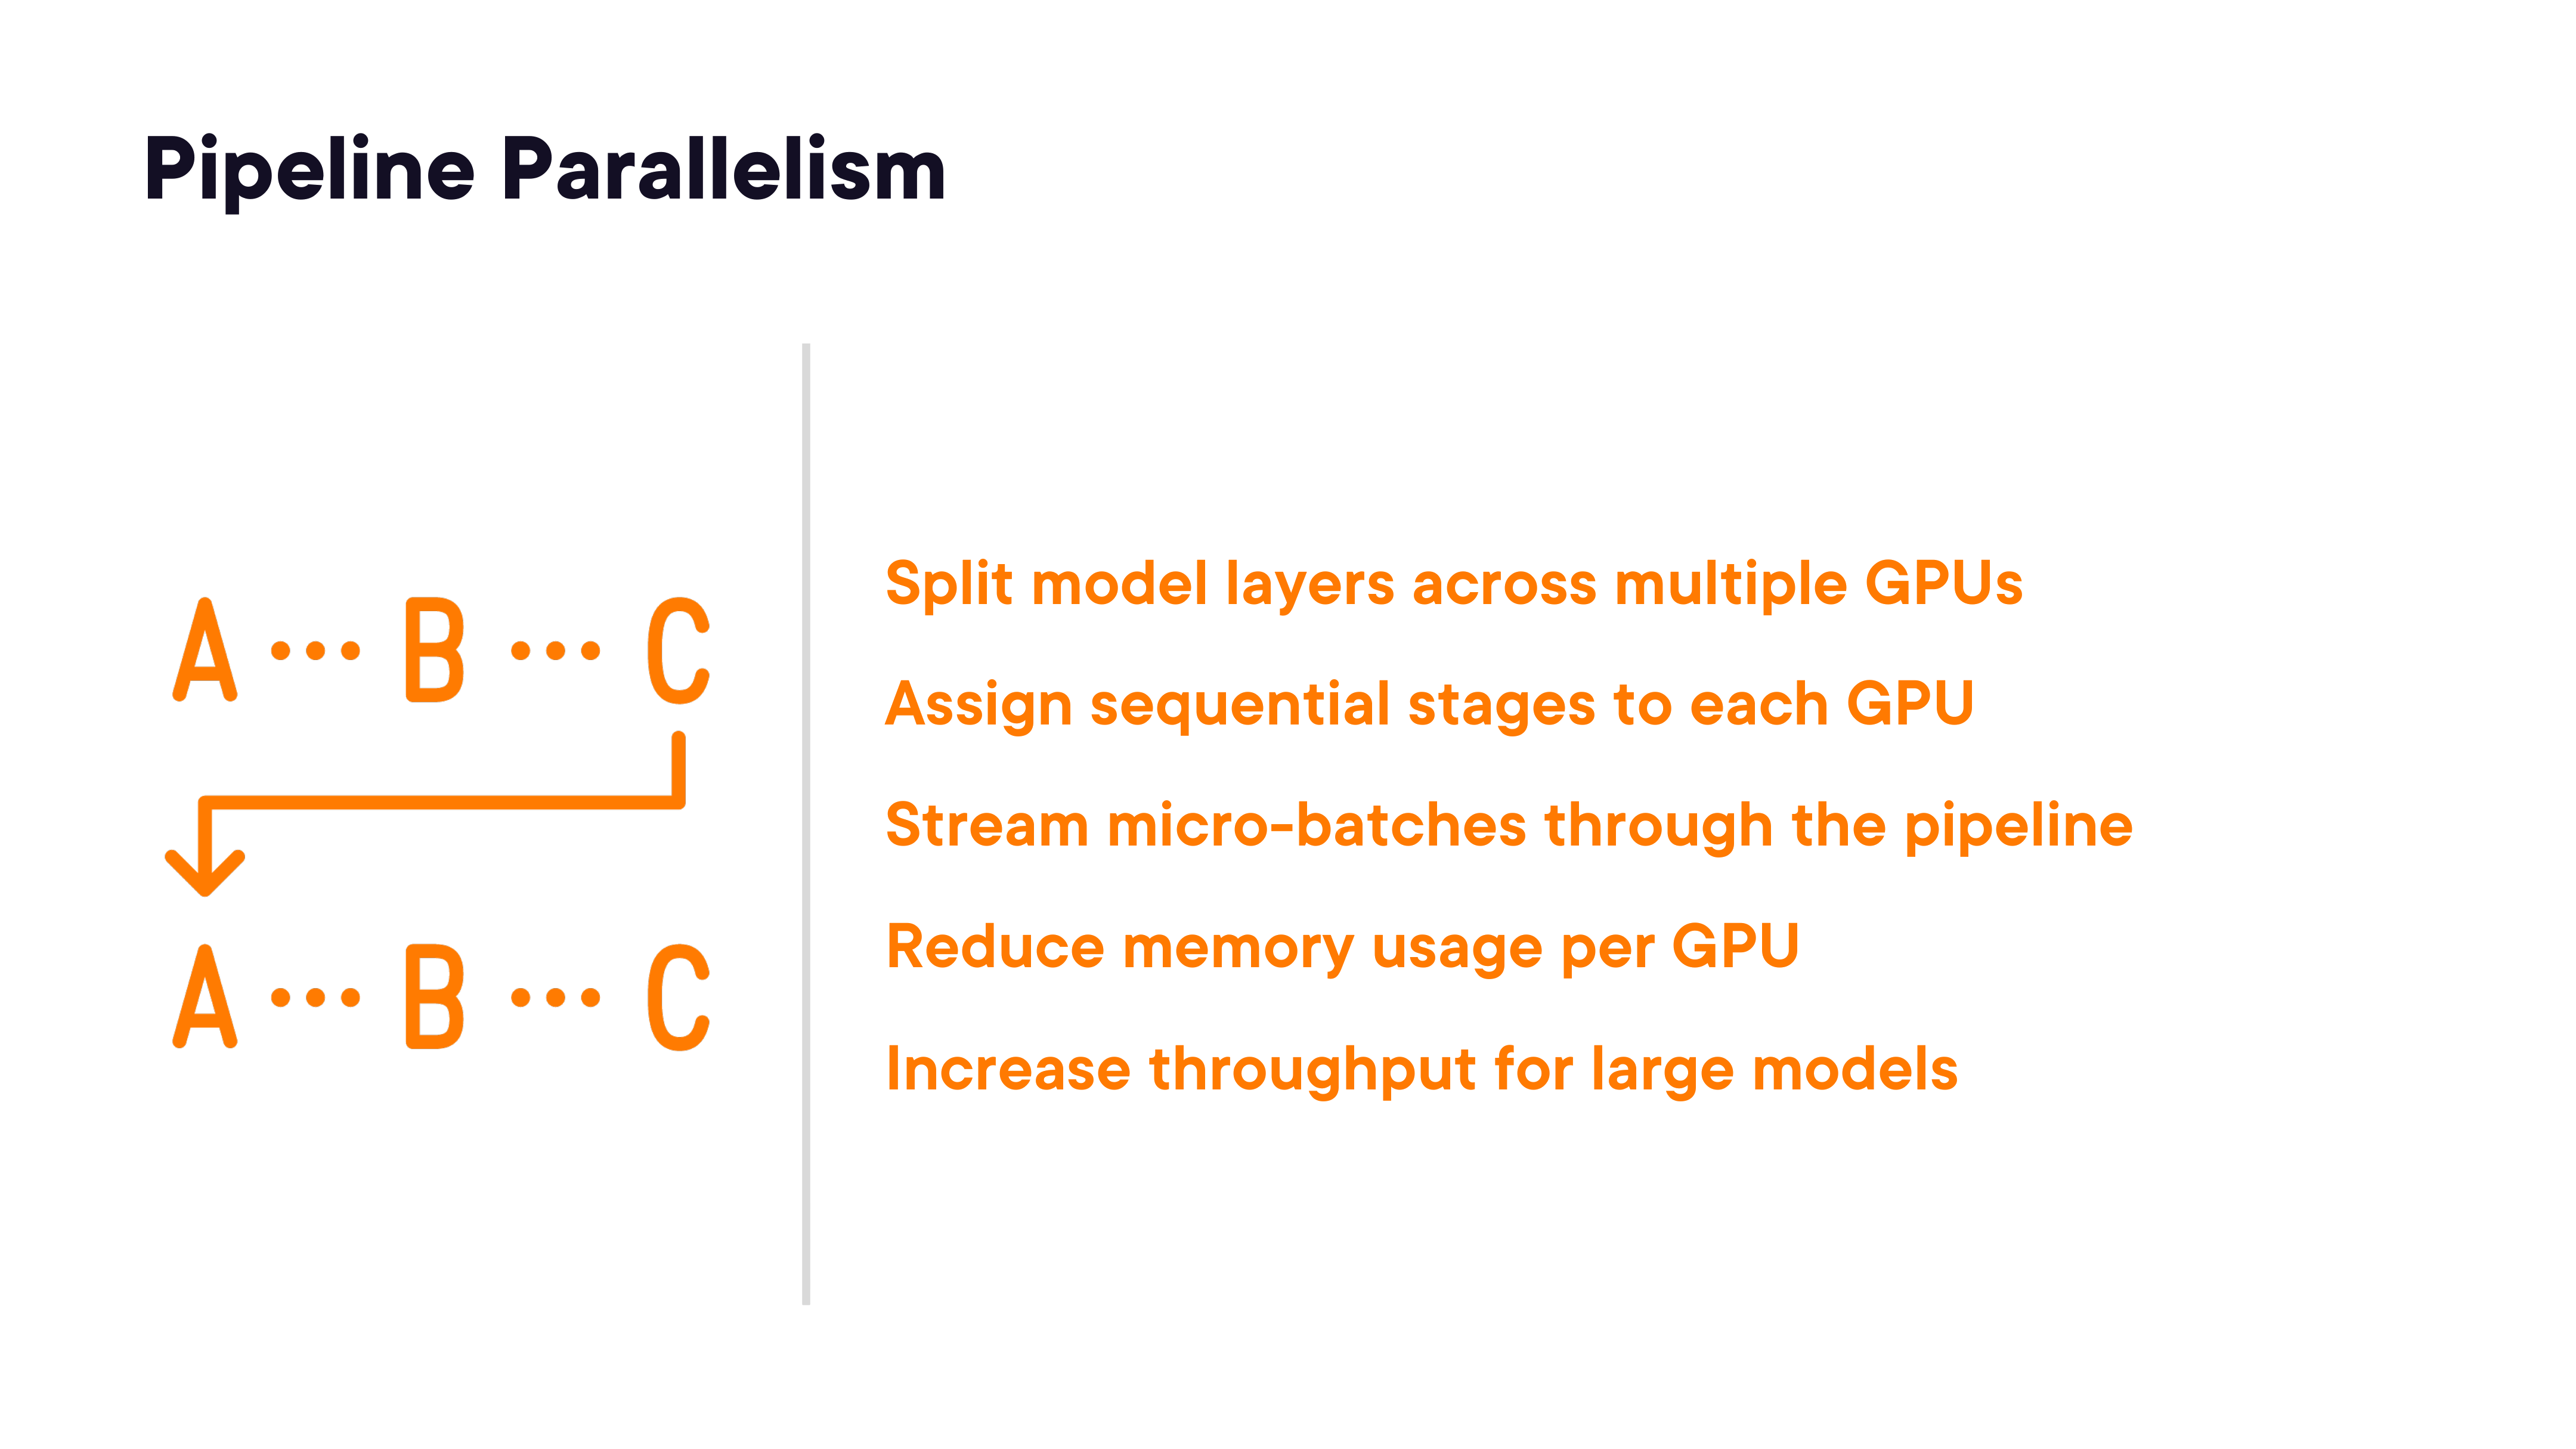

In [2]:
render_diagram(Path("assets/03-pipeline-parallelism.png"))

- Split model layers across multiple GPUs
- Assign sequential stages to each GPU
- Stream micro-batches through the pipeline to keep all GPUs active
- Reduce memory usage per GPU
- Increase throughput for large models

### Auto-scaling GPU Infrastructure

Auto-scaling dynamically adjusts GPU capacity based on workload demand to balance performance, responsiveness, and cost efficiency.

#### Scaling Metrics

| Metric | Description |
|---|---|
| **GPU utilization** | Percentage of active GPU compute |
| **Queue length** | Pending requests awaiting execution |
| **Warm-up time** | Latency for a new GPU instance to become ready |
| **Scaling latency** | Time from scale-out trigger to serving capacity |

#### Cost-efficient GPU Scaling

- Balance performance requirements with cost constraints
- Scale based on demand rather than fixed capacity
- Right-size GPU resources before scaling out
- Use lower-cost GPUs when latency allows
- Align scaling policies with SLAs and budgets

### Optimizing GPU Resources

#### Mixed-precision Inference

| Precision | Speed | Memory | Accuracy |
|---|---|---|---|
| **FP32** | Baseline | Baseline | Full |
| **FP16** | Faster | ~50% less | Minimal loss |
| **INT8** | Fastest | ~75% less | Requires calibration |

#### GPU Memory Management

- **Caching** — store frequently used data in GPU memory to reduce recomputation
- **Reuse** — reallocate existing GPU buffers across requests to minimize overhead

#### Kernel Optimizations for Throughput

- **Kernel fusion** — combine multiple operations into one GPU kernel to reduce memory round-trips
- **Memory coalescing** — align memory access patterns to maximize bandwidth
- **Shared memory** — exploit fast on-chip shared memory for repeated data access
- **Tensor cores** — route matrix multiplications through specialized hardware
- **Batch sizing** — tune batch size to maximize GPU occupancy

### Demo: GPU Speed

Compares FP32 vs FP16 inference timing and measures GPU memory utilization on a transformer model.

See [`03/demos.ipynb`](03/demos.ipynb) for the full demo.

<a id="module-04"></a>
## Module 04: Cost Engineering and Optimization Strategies

_Covers GenAI cost structures, cost monitoring and attribution, cost–quality trade-offs, and practical optimization techniques._

### Understanding GenAI Costs

#### Model Inference Costs

- **Per-token cost** — cost incurred for each generated or processed token during model inference
- **Per-request cost** — fixed cost charged per API call or request regardless of response length

#### Infrastructure Costs

| Driver | Description |
|---|---|
| **GPU scaling** | Provisioning larger or more GPUs for higher demand |
| **Utilization inefficiencies** | Paying for idle GPU capacity |
| **Storage components** | Model weights, embeddings, and KV-cache storage |
| **Performance storage** | High-throughput storage for fast model loading |
| **Networking overhead** | Data transfer between components |

#### Data Transfer and Hidden Costs

- Data egress fees across cloud boundaries
- Cross-region traffic increasing networking spend
- Preprocessing and embeddings adding compute overhead
- Logging and tracing increasing storage costs
- Retries and failures inflating effective spend
- Security controls adding operational overhead
- Pricing changes creating long-term cost risk

### Cost Monitoring and Attribution

#### Tracking Spending

- Attribute costs to users, applications, or tenants
- Identify high-cost features and workflows
- Compare costs across different model choices
- Analyze cost by request type
- Support optimization and budgeting decisions

#### Data-driven Cost Decisions

- Understand where GenAI spending is concentrated
- Identify high-cost, low-value workloads
- Compare cost per request and outcome
- Detect anomalies using cost benchmarks
- Forecast usage using historical cost trends

#### Cost Monitoring across Environments

Integrate cost and usage metrics with cloud and on-premises monitoring platforms. Correlate GenAI spending with infrastructure, application, and business metrics.

### Cost–Quality Trade-offs

#### Frontier Models vs. Smaller Models

| Consideration | Frontier Models | Smaller Models |
|---|---|---|
| Reasoning quality | Higher | Lower |
| Cost per token | Higher | Lower |
| Latency | Higher | Lower |
| Best for | Complex reasoning, multi-step tasks | Classification, summarization, structured output |

A **hybrid model strategy** routes simple requests to smaller models and complex requests to frontier models.

#### Cloud APIs vs. Self-hosting

> Cloud APIs offer faster time to value and lower operational overhead, while self-hosting provides greater cost control, customization, and predictability at scale.

#### Balancing Performance, Quality, and Cost

Key factors to weigh: latency requirements, output quality threshold, model selection strategy, hosting strategy, and budget constraints.

### Cost Optimization Techniques

#### Efficient Prompt and Response Reuse

| Technique | Description |
|---|---|
| **Prompt Compression** | Reduce prompt size to lower token usage and inference cost |
| **Response Caching** | Reuse cached responses for identical or semantically similar requests |

#### Request Batching

Combine multiple inference requests into a single batch to improve GPU utilization. Reduces per-request overhead and lowers overall inference cost.

#### Speculative Decoding and Quantization

- **Faster token generation** — speculative decoding skips large-model forward passes using a draft model
- **Improved inference throughput** — quantization reduces per-operation compute cost
- **Reduced memory footprint** — INT8/INT4 quantization cuts VRAM requirements
- **Lower GPU costs** — fewer and smaller GPU resources needed
- **Efficient hardware utilization** — more requests per GPU at steady state

### Demo: Cost Optimization

Demonstrates prompt compression, response caching, request batching, and FP16 quantization with before/after cost comparisons.

See [`04/demos.ipynb`](04/demos.ipynb) for the full demo.

<a id="module-05"></a>
## Module 05: Advanced Inference Techniques for Speed and Quality

_Covers speculative decoding, quantization methods, attention optimization, model compression, and efficient long-context serving._

### Introduction to Advanced Inference

Advanced inference techniques improve latency, throughput, and cost efficiency while preserving model output quality.

#### Advanced Inference Techniques Overview

| Technique | Primary Benefit |
|---|---|
| **Speculative Decoding** | Reduces latency via draft-model token prefill |
| **Quantization** | Reduces memory and improves speed via lower precision |
| **Attention Optimization** | Reduces memory access cost for attention computation |
| **Compression** | Reduces model size via distillation, pruning, or low-rank adaptation |

#### Trade-offs: Speed, Memory, and Quality

- Faster inference often reduces output quality
- Lower memory limits model capacity
- Higher quality increases latency and memory
- Quantization improves speed with quality trade-offs
- Attention optimizations reduce memory overhead
- Optimal balance depends on workload requirements

### Speculative Decoding

Speculative decoding uses a smaller draft model to generate candidate tokens that are efficiently verified by a larger model, reducing latency while preserving output quality.

#### How Speculative Decoding Works

1. Smaller draft model generates several candidate tokens ahead of time
2. The draft model is optimized for speed and low latency
3. A larger verification model evaluates the draft tokens in parallel
4. Matching tokens are accepted without recomputation
5. Incorrect tokens are discarded and regenerated by the large model

#### When and Why to Use Speculative Decoding

| Factor | Consideration |
|---|---|
| **Latency reduction** | Most effective when draft model acceptance rate is high |
| **Real-time inference** | Suited for interactive, low-latency applications |
| **Large models** | Benefit is proportional to the size gap between draft and verification model |
| **Draft alignment** | Draft model must be trained on similar distribution |
| **Quality preservation** | Output quality is identical to running the large model alone |
| **Divergence risk** | If draft tokens are frequently rejected, overhead increases |

### Quantization

Quantization reduces model precision to lower memory usage and improve inference speed, enabling large language models to run efficiently on cost-effective hardware.

#### Quantization Techniques

| Technique | Description |
|---|---|
| **INT8** | 8-bit integer quantization; balanced performance, minimal accuracy loss |
| **INT4** | 4-bit integer quantization; maximum compression, higher accuracy risk |
| **GPTQ** | Post-training quantization optimized for GPT-style models |
| **AWQ** | Activation-aware weight quantization; preserves critical weights |

#### Lower Precision Trade-offs

- Faster inference and reduced memory usage
- Potential accuracy loss (higher at INT4)
- INT8 offers balanced performance for most use cases
- INT4 carries higher quality risk for complex reasoning tasks

#### Choosing the Right Quantization Method

1. **Identify primary constraint** — memory, latency, or cost
2. **Start with INT8** — widely supported, minimal quality impact
3. **Use INT4 or GPTQ** when memory is the binding constraint
4. **Benchmark real workloads** — synthetic benchmarks can miss task-specific degradation
5. **Validate production performance** — monitor output quality after deployment

### Attention Optimization

Attention optimization reduces memory usage and improves throughput when serving transformer models at scale, enabling efficient handling of long sequences and concurrent requests.

#### Attention Optimization Techniques

| Technique | Description |
|---|---|
| **FlashAttention** | Fuses attention operations to reduce memory bandwidth usage for faster attention |
| **Paged Attention** | Manages KV-cache in fixed-size pages, enabling efficient memory reuse across requests |
| **Continuous Batching** | Improves throughput by batching live requests without waiting for all to complete |

#### Implementing Attention Optimization — Best Practices

- Enable FlashAttention for faster, memory-efficient attention
- Use paged attention for variable-length inputs
- Control KV-cache growth for long sequences
- Combine continuous batching for higher throughput
- Profile latency and memory impact regularly

### Model Compression

Model compression techniques reduce model size and speed up inference while preserving acceptable output quality.

#### Model Compression Techniques

| Technique | Mechanism |
|---|---|
| **Distillation** | Train a smaller student model to mimic a larger teacher model's outputs |
| **Pruning** | Remove low-importance weights or attention heads from the trained model |
| **Low-rank adaptation** | Approximate weight matrices with lower-rank decompositions |

#### Trade-offs on Output Quality

- All techniques improve speed but risk quality loss
- Distillation loses rare reasoning capabilities not captured by the teacher signal
- Pruning may remove weights critical for edge cases
- Low-rank adaptation limits expressiveness for specialized tasks
- Aggressive compression increases hallucination rates
- Impact varies by task — evaluate on task-specific benchmarks

### Efficient Long-context Serving

Long context inputs significantly increase memory usage and inference latency in transformer-based models.

#### Why Long Sequences Are Costly

- Attention cost grows **quadratically** with sequence length
- KV-cache memory grows linearly with context size per request
- Prefill latency increases for long inputs
- Throughput drops with naive long-context serving
- Memory pressure limits the number of concurrent requests

#### FlashAttention, Paged Attention, and KV-cache Reuse

| Technique | How It Helps Long Contexts |
|---|---|
| **FlashAttention** | Computes attention in tiles to avoid materializing the full attention matrix |
| **Paged Attention** | Allocates KV-cache in fixed pages, reducing fragmentation and enabling sharing |
| **KV-cache reuse** | Reuses prefix computations across requests with shared context |

#### Trade-offs: Optimizing Memory vs. Latency

- **Memory–latency coupling** — reducing memory often increases compute per token
- **KV-cache growth** — prefill of long contexts dominates memory at steady state
- **Attention optimizations** — FlashAttention improves speed but requires kernel-level support
- **Batch size trade-offs** — larger batches improve throughput but increase per-request memory
- **Retrieval-based inference** — an alternative to long context: retrieve only the relevant chunk

### Demo: Smart Inference

Demonstrates full-context inference, a toy retrieval-based approach, and a smart inference router that selects the optimal strategy based on input token count.

See [`05/demos.ipynb`](05/demos.ipynb) for the full demo.